/var/folders/2_/r_w1bxyd7yj52gcl_l7jdl2r0000gn/T/ipykernel_8933/2049022940.py:29: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3)


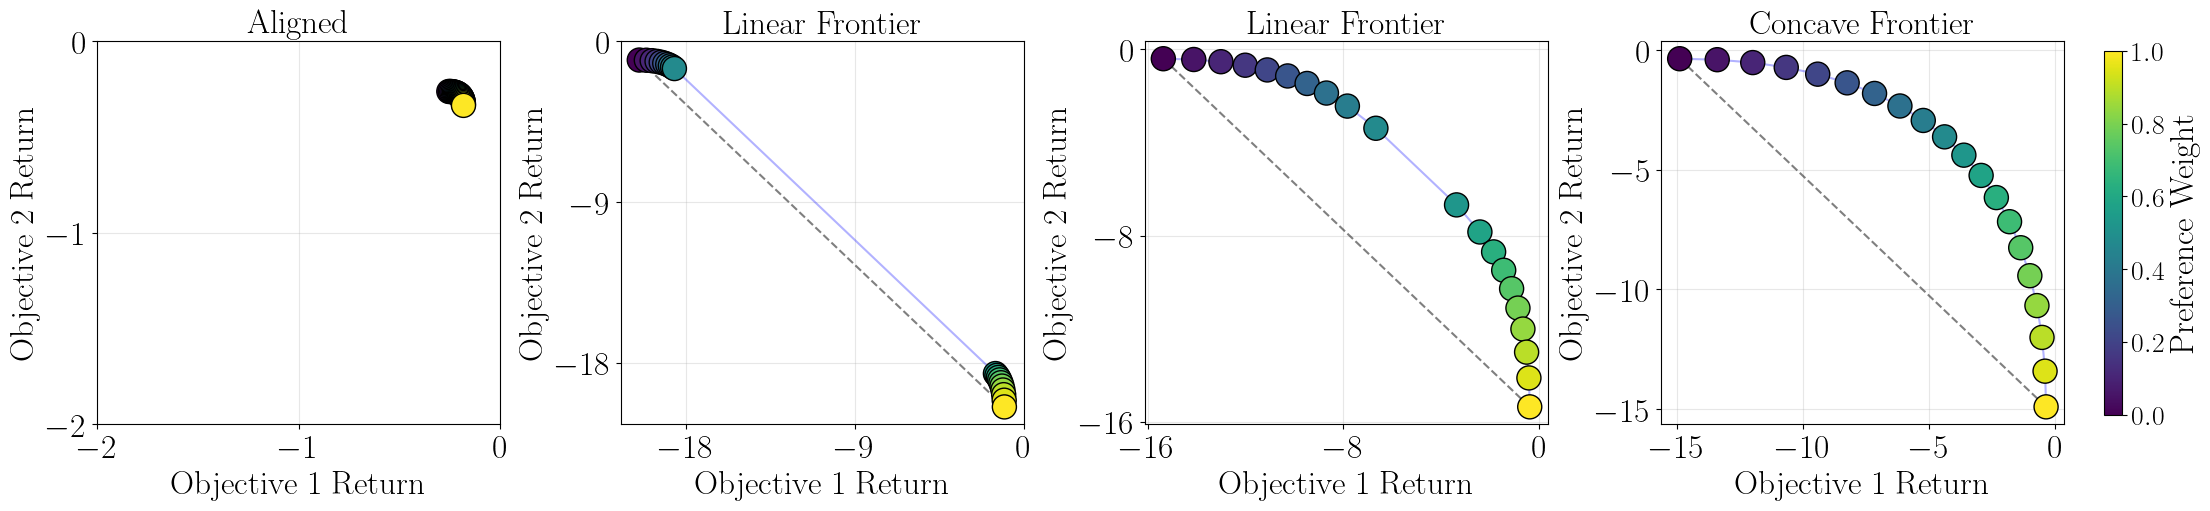

In [39]:
import json
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import rc

rc('font',**{'family':'sans-serif','sans-serif':['Helvetica']})
mpl.rcParams['savefig.dpi'] = 1200
mpl.rcParams['text.usetex'] = True  # not really needed

import matplotlib.ticker as mticker


# Input/output (no CLI args; edit here if needed)
JSON_FILE = "case_data.json"

data = json.loads(Path(JSON_FILE).read_text(encoding="utf-8"))
modes = data["modes"]
titles = [
      r"$\mathrm{Aligned}$",
      r"$\mathrm{Linear~Frontier}$",
      r"$\mathrm{Linear~Frontier}$",
      r"$\mathrm{Concave~Frontier}$"
    ]
w_values = np.array(data["w_values"], dtype=float)

fig, axes = plt.subplots(1, len(modes), figsize=(22, 5), constrained_layout=True)
plt.subplots_adjust(wspace=0.3)
if len(modes) == 1:
    axes = [axes]

sc = None
fontsize = 24

for i, mode in enumerate(modes):
    case = data["cases"][mode]
    r1 = np.array(case["r1"], dtype=float)
    r2 = np.array(case["r2"], dtype=float)

    ax = axes[i]

    if mode != "aligned":
        ax.plot([r1[0], r1[-1]], [r2[0], r2[-1]], "k--", alpha=0.5, label=r"$\mathrm{Convex~Hull~(Mixing)}$")

    sc = ax.scatter(
        r1,
        r2,
        c=w_values,
        cmap="viridis",
        s=300,
        zorder=5,
        edgecolor="k",
    )
    ax.plot(r1, r2, "b-", alpha=0.3)

    ax.set_title(titles[i], fontsize=fontsize, fontweight="bold")
    if mode == 'aligned':
        ax.set_xticks([-2, -1, 0])
        ax.tick_params(labelsize=fontsize)
        ax.set_yticks([-2, -1, 0])
        ax.tick_params(labelsize=fontsize)
    elif mode == 'linear':
        ax.set_xticks([-18, -9, 0])
        ax.tick_params(labelsize=fontsize)
        ax.set_yticks([-18, -9, 0])
        ax.tick_params(labelsize=fontsize)
    elif mode == 'linear2':
        ax.set_xticks([-16, -8, 0])
        ax.tick_params(labelsize=fontsize)
        ax.set_yticks([-16, -8, 0])
        ax.tick_params(labelsize=fontsize)
    elif mode == 'concave':
        ax.set_xticks([-15, -10, -5, 0])
        ax.tick_params(labelsize=fontsize)
        ax.set_yticks([-15, -10, -5, 0])
        ax.tick_params(labelsize=fontsize)
    ax.set_xlabel(r"$\mathrm{Objective}~1~\mathrm{Return}$", fontsize=fontsize)
    ax.set_ylabel(r"$\mathrm{Objective}~2~\mathrm{Return}$", fontsize=fontsize)
    ax.grid(True, alpha=0.3)

# cbar_ax = fig.add_axes([0.92, 0.15, 0.01, 0.7])
# fig.colorbar(sc, cax=cbar_ax, label="Preference Weight $w$ (0=Obj2, 1=Obj1)")
cbar = fig.colorbar(
    sc,
    ax=axes,
    location="right",
    pad=0.02,
    shrink=0.95
)
cbar.ax.tick_params(labelsize=20)
cbar.set_label(
    r"$\mathrm{Preference~Weight}$",
    fontsize=24
)
fig.savefig('case.pdf', dpi=1200, bbox_inches="tight")

plt.show()

plt.close(fig)


